# Network Threat Detector on CICIDS2017



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Installing packages

ExecuTorch is needed only for step 8 (exporting the `.pte`). If its install fails, everything else still works.

In [ ]:
!pip install -q executorch pytorch-tokenizers
import sklearn, sys
print("Python", sys.version.split()[0], "| scikit-learn", sklearn.__version__)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Python 3.13.16 | scikit-learn 1.9.1


## 2. Get the data


In [ ]:
import os, zipfile
USE_DRIVE = True
DRIVE_ZIP = "/content/drive/Shared with me/SOC DATASETS/cicids.zip"   # change if you put it in a folder
CSV_NAME = "cicids2017_cleaned.csv"

if not os.path.exists(CSV_NAME):
    if os.path.exists("cicids.zip"):
        zip_path = "cicids.zip"
    elif USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        zip_path = DRIVE_ZIP
    else:
        from google.colab import files
        uploaded = files.upload()          # pick cicids.zip
        zip_path = list(uploaded)[0]
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(".")
print(CSV_NAME, round(os.path.getsize(CSV_NAME) / 1e6), "MB")

cicids2017_cleaned.csv 717 MB


## 3. Load and clean

In [7]:
import numpy as np, pandas as pd
LABEL = "Attack Type"
NORMAL = "Normal Traffic"
SEED = 42

df = pd.read_csv(CSV_NAME)
print("Raw shape:", df.shape)
num_cols = [c for c in df.columns if c != LABEL]
df[num_cols] = df[num_cols].astype("float32")                  # halves memory
df[num_cols] = df[num_cols].replace([np.inf, -np.inf], np.nan).fillna(0)
before = len(df)
df = df.drop_duplicates()
print(f"Removed {before - len(df):,} duplicate rows -> {len(df):,} rows, {len(num_cols)} features")
print(df[LABEL].value_counts())

Raw shape: (2520751, 53)
Removed 22,992 duplicate rows -> 2,497,759 rows, 52 features
Attack Type
Normal Traffic    2072080
DoS                193730
DDoS               128014
Port Scanning       90694
Brute Force          9150
Web Attacks          2143
Bots                 1948
Name: count, dtype: int64


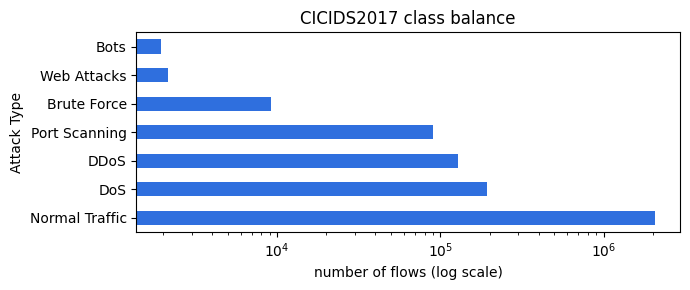

In [8]:
import matplotlib.pyplot as plt
ax = df[LABEL].value_counts().plot.barh(logx=True, figsize=(7, 3), color="#2f6fde")
ax.set_xlabel("number of flows (log scale)"); ax.set_title("CICIDS2017 class balance"); plt.tight_layout(); plt.show()

## 4. Balance and split
Normal traffic is 83% of the data. We keep **300,000 normal flows** plus **all attack flows**, then split 80/20 (stratified).
The ~1.8 million normal flows we did not use are kept aside to measure the **false alarm rate** on traffic the model never saw (step 6).

In [9]:
from sklearn.model_selection import train_test_split
N_NORMAL = 300_000
normal = df[df[LABEL] == NORMAL]
normal_used = normal.sample(N_NORMAL, random_state=SEED)
normal_unused = normal.drop(normal_used.index)
data = pd.concat([normal_used, df[df[LABEL] != NORMAL]]).reset_index(drop=True)
del df, normal   # free RAM

FEATURES = num_cols
CLASSES = sorted(data[LABEL].unique())
X, y = data[FEATURES], data[LABEL]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("train", X_train.shape, "test", X_test.shape, "unused normal", normal_unused.shape)

train (580543, 52) test (145136, 52) unused normal (1772080, 53)


## 5. Main model: HistGradientBoosting (scikit-learn)


Trained in 58.8s
                precision    recall  f1-score   support

          Bots     0.8986    0.9794    0.9373       389
   Brute Force     0.9989    0.9989    0.9989      1830
          DDoS     0.9998    1.0000    0.9999     25603
           DoS     0.9988    0.9997    0.9993     38746
Normal Traffic     0.9997    0.9980    0.9988     60000
 Port Scanning     0.9983    0.9994    0.9989     18139
   Web Attacks     0.9839    1.0000    0.9919       429

      accuracy                         0.9989    145136
     macro avg     0.9826    0.9965    0.9893    145136
  weighted avg     0.9990    0.9989    0.9990    145136

{'accuracy': 0.9989, 'macro_f1': 0.9893, 'binary_attack_precision': 0.9986, 'binary_attack_recall': 0.9998, 'train_seconds': 58.8053}


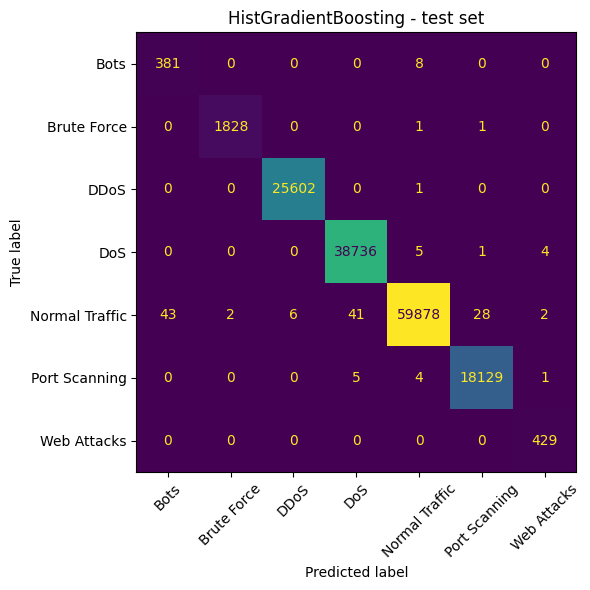

In [10]:
import time, json
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

hgb = HistGradientBoostingClassifier(max_iter=200, class_weight="balanced", random_state=SEED)
t0 = time.time(); hgb.fit(X_train, y_train); train_s = time.time() - t0
pred = hgb.predict(X_test)
print(f"Trained in {train_s:.1f}s")
print(classification_report(y_test, pred, digits=4))

# Binary view: attack vs normal
yt_bin, yp_bin = (y_test != NORMAL), (pred != NORMAL)
hgb_metrics = {
    "accuracy": accuracy_score(y_test, pred),
    "macro_f1": f1_score(y_test, pred, average="macro"),
    "binary_attack_precision": precision_score(yt_bin, yp_bin),
    "binary_attack_recall": recall_score(yt_bin, yp_bin),
    "per_class": classification_report(y_test, pred, output_dict=True),
    "train_seconds": train_s,
}
print({k: round(v, 4) for k, v in hgb_metrics.items() if isinstance(v, float)})

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=CLASSES), display_labels=CLASSES).plot(ax=ax, xticks_rotation=45, colorbar=False, values_format="d")
ax.set_title("HistGradientBoosting - test set"); plt.tight_layout()
os.makedirs("network_artifacts", exist_ok=True)
plt.savefig("network_artifacts/confusion_matrix.png", dpi=150); plt.show()

## 6. False alarm rate on normal traffic the model never saw

In [11]:
sample_unused = normal_unused.sample(min(300_000, len(normal_unused)), random_state=SEED)
fa = (hgb.predict(sample_unused[FEATURES]) != NORMAL).mean()
hgb_metrics["false_alarm_rate_unseen_normal"] = float(fa)
hgb_metrics["unseen_normal_checked"] = len(sample_unused)
print(f"False alarm rate on {len(sample_unused):,} unseen normal flows: {fa:.4%}")

False alarm rate on 300,000 unseen normal flows: 0.1927%


## 7. Latency, size, and the explanation statistics


In [12]:
import joblib

def slog(a):  # signed log: tames huge values like bytes/s
    return np.sign(a) * np.log1p(np.abs(a))

normal_train = X_train[y_train == NORMAL].values
normal_mean = slog(normal_train).mean(0)
normal_std = slog(normal_train).std(0) + 1e-6

bundle = {
    "model": hgb, "features": FEATURES, "classes": CLASSES, "normal_label": NORMAL,
    "normal_slog_mean": normal_mean.astype("float32"), "normal_slog_std": normal_std.astype("float32"),
    "sklearn_version": sklearn.__version__,
}
joblib.dump(bundle, "network_artifacts/network_detector.joblib", compress=3)
# Same info as plain JSON, so the .pte backend works without scikit-learn
with open("network_artifacts/network_meta.json", "w") as f:
    json.dump({"features": FEATURES, "classes": CLASSES, "normal_label": NORMAL,
               "normal_slog_mean": normal_mean.tolist(), "normal_slog_std": normal_std.tolist()}, f)
size_kb = os.path.getsize("network_artifacts/network_detector.joblib") / 1024

one = X_test.iloc[[0]]
hgb.predict_proba(one)
lat = []
for i in range(300):
    row = X_test.iloc[[i]]; t = time.perf_counter(); hgb.predict_proba(row); lat.append((time.perf_counter() - t) * 1000)
hgb_metrics.update({"model_file_kb": size_kb, "latency_ms_single_flow_mean": float(np.mean(lat)),
                    "latency_ms_single_flow_p95": float(np.percentile(lat, 95))})
t = time.perf_counter(); hgb.predict(X_test); batch_s = time.perf_counter() - t
hgb_metrics["batch_flows_per_second"] = len(X_test) / batch_s
print(f"Model file {size_kb:.0f} KB | one flow {np.mean(lat):.2f} ms | batch {len(X_test)/batch_s:,.0f} flows/s")

Model file 447 KB | one flow 3.84 ms | batch 66,507 flows/s


## 8. Same task as a small neural network, exported to ExecuTorch (`.pte`)


In [13]:
import torch, torch.nn as nn
torch.manual_seed(SEED)

class FlowNet(nn.Module):
    def __init__(self, mean, std, n_in, n_out):
        super().__init__()
        self.register_buffer("mean", torch.tensor(mean, dtype=torch.float32))
        self.register_buffer("std", torch.tensor(std, dtype=torch.float32))
        self.net = nn.Sequential(nn.Linear(n_in, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, n_out))
    def logits(self, x):
        x = torch.sign(x) * torch.log1p(torch.abs(x))
        return self.net((x - self.mean) / self.std)
    def forward(self, x):                      # returns class probabilities
        return torch.softmax(self.logits(x), dim=-1)

all_slog = slog(X_train.values)
mlp = FlowNet(all_slog.mean(0), all_slog.std(0) + 1e-6, len(FEATURES), len(CLASSES))
cls_idx = {c: i for i, c in enumerate(CLASSES)}
Xt = torch.tensor(X_train.values, dtype=torch.float32); yt = torch.tensor(y_train.map(cls_idx).values)
counts = np.bincount(yt.numpy()); weights = torch.tensor((len(yt) / (len(counts) * counts)) ** 0.5, dtype=torch.float32)
opt = torch.optim.Adam(mlp.parameters(), lr=1e-3); loss_fn = nn.CrossEntropyLoss(weight=weights)
t0 = time.time()
for epoch in range(8):
    perm = torch.randperm(len(Xt))
    for i in range(0, len(Xt), 1024):
        idx = perm[i:i + 1024]
        opt.zero_grad(); loss = loss_fn(mlp.logits(Xt[idx]), yt[idx]); loss.backward(); opt.step()
    print(f"epoch {epoch + 1}: loss {loss.item():.4f}")
mlp.eval()
with torch.no_grad():
    mlp_pred = np.array(CLASSES)[mlp(torch.tensor(X_test.values, dtype=torch.float32)).argmax(1).numpy()]
mlp_metrics = {"accuracy": accuracy_score(y_test, mlp_pred), "macro_f1": f1_score(y_test, mlp_pred, average="macro"),
               "per_class": classification_report(y_test, mlp_pred, output_dict=True), "train_seconds": time.time() - t0}
print(classification_report(y_test, mlp_pred, digits=4))

epoch 1: loss 0.0195
epoch 2: loss 0.0242
epoch 3: loss 0.0180
epoch 4: loss 0.0447
epoch 5: loss 0.0164
epoch 6: loss 0.0199
epoch 7: loss 0.0265
epoch 8: loss 0.0154
                precision    recall  f1-score   support

          Bots     0.5993    0.8689    0.7093       389
   Brute Force     0.9989    0.9885    0.9937      1830
          DDoS     0.9998    0.9996    0.9997     25603
           DoS     0.9972    0.9939    0.9956     38746
Normal Traffic     0.9962    0.9929    0.9945     60000
 Port Scanning     0.9983    0.9991    0.9987     18139
   Web Attacks     0.7150    0.9883    0.8297       429

      accuracy                         0.9947    145136
     macro avg     0.9007    0.9759    0.9316    145136
  weighted avg     0.9955    0.9947    0.9950    145136



In [14]:
try:
    from executorch.exir import to_edge_transform_and_lower
    from executorch.backends.xnnpack.partition.xnnpack_partitioner import XnnpackPartitioner
    from executorch.runtime import Runtime

    exported = torch.export.export(mlp, (torch.zeros(1, len(FEATURES)),))
    program = to_edge_transform_and_lower(exported, partitioner=[XnnpackPartitioner()]).to_executorch()
    with open("network_artifacts/network_mlp.pte", "wb") as f:
        f.write(program.buffer)

    # Check the .pte gives the same answer as PyTorch, and time it
    method = Runtime.get().load_program("network_artifacts/network_mlp.pte").load_method("forward")
    x = torch.tensor(X_test.values[:1], dtype=torch.float32)
    with torch.no_grad():
        diff = float((method.execute([x])[0] - mlp(x)).abs().max())
    lat = []
    for i in range(300):
        x = torch.tensor(X_test.values[i:i + 1], dtype=torch.float32)
        t = time.perf_counter(); method.execute([x]); lat.append((time.perf_counter() - t) * 1000)
    mlp_metrics.update({"pte_kb": os.path.getsize("network_artifacts/network_mlp.pte") / 1024,
                        "pte_vs_pytorch_max_diff": diff, "pte_latency_ms_mean": float(np.mean(lat))})
    print(f".pte {mlp_metrics['pte_kb']:.0f} KB | max difference vs PyTorch {diff:.2e} | {np.mean(lat):.3f} ms per flow")
except Exception as e:
    print("ExecuTorch export skipped:", type(e).__name__, e)

W1124 16:28:29.237000 385 torch/utils/_pytree.py:646] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


.pte 66 KB | max difference vs PyTorch 2.68e-09 | 0.096 ms per flow


## 9. Save metrics, demo samples, and download everything

In [15]:
sample = pd.concat([X_test[y_test == c].sample(min(10, (y_test == c).sum()), random_state=SEED).assign(**{LABEL: c}) for c in CLASSES])
sample.to_csv("network_artifacts/sample_flows.csv", index=False)

metrics = {
    "dataset": {"name": "CIC-IDS2017 (cleaned)", "rows_after_dedup": int(len(data) + len(normal_unused)),
                "rows_used": int(len(data)), "normal_used": N_NORMAL, "features": len(FEATURES),
                "classes": CLASSES, "test_rows": int(len(X_test))},
    "histgradientboosting": hgb_metrics,
    "mlp_executorch": mlp_metrics,
    "versions": {"sklearn": sklearn.__version__, "torch": torch.__version__},
}
with open("network_artifacts/network_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2, default=float)

!cd network_artifacts && ls -la
!zip -qr network_artifacts.zip network_artifacts
try:
    from google.colab import files
    files.download("network_artifacts.zip")
except ImportError:
    print("Not in Colab: network_artifacts.zip is in the current folder")

total 640
drwxr-xr-x 2 root root   4096 Nov 24 16:28 .
drwxr-xr-x 1 root root   4096 Nov 24 16:22 ..
-rw-r--r-- 1 root root  79463 Nov 24 16:22 confusion_matrix.png
-rw-r--r-- 1 root root 457497 Nov 24 16:27 network_detector.joblib
-rw-r--r-- 1 root root   3220 Nov 24 16:27 network_meta.json
-rw-r--r-- 1 root root   4463 Nov 24 16:28 network_metrics.json
-rw-r--r-- 1 root root  67484 Nov 24 16:28 network_mlp.pte
-rw-r--r-- 1 root root  24358 Nov 24 16:28 sample_flows.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Deploy it in the app
1. Unzip `network_artifacts.zip` into `sms-scam-detector/models/network/` (so you have `models/network/network_detector.joblib` etc.).
2. On the device, install the **same scikit-learn version** printed in step 1 (`pip install scikit-learn==X.Y.Z`); joblib files can break across versions. The `.pte` file does not have this problem.
3. Run `streamlit run app/app.py` and open the **Network Threats** page in the sidebar. Upload a CSV with the same 52 columns (for example `sample_flows.csv`, or flows exported by CICFlowMeter), pick a flow, and Llama explains the verdict.

**Limitations to mention in the report:** CIC-IDS2017 was recorded in a lab in 2017; scores this high are typical for this dataset and usually drop on real networks. Live use needs a flow extractor such as CICFlowMeter producing the same 52 features.